# TA-03: Sistem Prediksi Risiko Gagal Bayar Kartu Kredit
## Menggunakan Logistic Regression dan SMOTE

Notebook ini bertujuan membangun model klasifikasi biner untuk memprediksi
kemungkinan nasabah mengalami gagal bayar kartu kredit pada bulan berikutnya.

Tahapan penelitian:
1. Import library dan membaca dataset.
2. Exploratory Data Analysis (EDA).
3. Pembersihan dan preprocessing data.
4. Pembagian data latih dan data uji.
5. Training Logistic Regression tanpa SMOTE dan dengan SMOTE.
6. Evaluasi menggunakan Confusion Matrix, Precision, Recall, F1-Score,
   dan ROC-AUC.
7. Interpretasi model dari sudut pandang manajemen risiko.
8. Penyimpanan model untuk integrasi dengan aplikasi Flask dan Vercel.

Target:
- 0 = Tidak mengalami gagal bayar pada bulan berikutnya.
- 1 = Mengalami gagal bayar pada bulan berikutnya.


In [1]:
%pip install -U pandas numpy matplotlib seaborn scikit-learn imbalanced-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

import joblib

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

RANDOM_STATE = 42

print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Imbalanced-learn:", imblearn.__version__)
print("Semua library berhasil diimpor.")

Pandas: 3.1.0
Scikit-learn: 1.9.1
Imbalanced-learn: 0.14.2
Semua library berhasil diimpor.


In [3]:
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

DATA_PATH = PROJECT_ROOT / "data" / "UCI_Credit_Card.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATA_PATH}\n"
        "Periksa nama file dan lokasi folder data."
    )

df = pd.read_csv(DATA_PATH)

print("Lokasi dataset:", DATA_PATH)
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Lokasi dataset: d:\Semester5 ML\TA3_301240032\data\UCI_Credit_Card.csv
Jumlah baris: 30000
Jumlah kolom: 25


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,"20,000.0000",2,2,1,24,2,2,-1,-1,-2,-2,"3,913.0000","3,102.0000",689.0000,0.0000,0.0000,0.0000,0.0000,689.0000,0.0000,0.0000,0.0000,0.0000,1
1,2,"120,000.0000",2,2,2,26,-1,2,0,0,0,2,"2,682.0000","1,725.0000","2,682.0000","3,272.0000","3,455.0000","3,261.0000",0.0000,"1,000.0000","1,000.0000","1,000.0000",0.0000,"2,000.0000",1
2,3,"90,000.0000",2,2,2,34,0,0,0,0,0,0,"29,239.0000","14,027.0000","13,559.0000","14,331.0000","14,948.0000","15,549.0000","1,518.0000","1,500.0000","1,000.0000","1,000.0000","1,000.0000","5,000.0000",0
3,4,"50,000.0000",2,2,1,37,0,0,0,0,0,0,"46,990.0000","48,233.0000","49,291.0000","28,314.0000","28,959.0000","29,547.0000","2,000.0000","2,019.0000","1,200.0000","1,100.0000","1,069.0000","1,000.0000",0
4,5,"50,000.0000",1,2,1,57,-1,0,-1,0,0,0,"8,617.0000","5,670.0000","35,835.0000","20,940.0000","19,146.0000","19,131.0000","2,000.0000","36,681.0000","10,000.0000","9,000.0000",689.0000,679.0000,0


In [4]:
print("Nama kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe().T)

print("\nMissing values per kolom:")
display(
    df.isnull().sum()
    .sort_values(ascending=False)
    .to_frame("Jumlah Missing Values")
)

print("\nJumlah baris duplikat:", df.duplicated().sum())

Nama kolom:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PA

,count,mean,std,min,25%,50%,75%,max
ID,"30,000.0000","15,000.5000","8,660.3984",1.0000,"7,500.7500","15,000.5000","22,500.2500","30,000.0000"
LIMIT_BAL,"30,000.0000","167,484.3227","129,747.6616","10,000.0000","50,000.0000","140,000.0000","240,000.0000","1,000,000.0000"
SEX,"30,000.0000",1.6037,0.4891,1.0000,1.0000,2.0000,2.0000,2.0000
EDUCATION,"30,000.0000",1.8531,0.7903,0.0000,1.0000,2.0000,2.0000,6.0000
MARRIAGE,"30,000.0000",1.5519,0.5220,0.0000,1.0000,2.0000,2.0000,3.0000
AGE,"30,000.0000",35.4855,9.2179,21.0000,28.0000,34.0000,41.0000,79.0000
PAY_0,"30,000.0000",-0.0167,1.1238,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_2,"30,000.0000",-0.1338,1.1972,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_3,"30,000.0000",-0.1662,1.1969,-2.0000,-1.0000,0.0000,0.0000,8.0000
PAY_4,"30,000.0000",-0.2207,1.1691,-2.0000,-1.0000,0.0000,0.0000,8.0000



Missing values per kolom:


,Jumlah Missing Values
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0



Jumlah baris duplikat: 0


In [5]:
TARGET = "default.payment.next.month"

FEATURES = [
    "LIMIT_BAL",
    "AGE",
    "EDUCATION",
    "MARRIAGE",
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "BILL_AMT1",
    "PAY_AMT1"
]

required_columns = FEATURES + [TARGET]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {missing_columns}\n"
        "Periksa nama kolom pada dataset."
    )

df = df[required_columns].copy()

print("Fitur yang digunakan:")
print(FEATURES)

print("\nTarget:", TARGET)
print("Ukuran data awal:", df.shape)

display(df.head())

Fitur yang digunakan:
['LIMIT_BAL', 'AGE', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'BILL_AMT1', 'PAY_AMT1']

Target: default.payment.next.month
Ukuran data awal: (30000, 10)


,LIMIT_BAL,AGE,EDUCATION,MARRIAGE,PAY_0,PAY_2,PAY_3,BILL_AMT1,PAY_AMT1,default.payment.next.month
0,"20,000.0000",24,2,1,2,2,-1,"3,913.0000",0.0000,1
1,"120,000.0000",26,2,2,-1,2,0,"2,682.0000",0.0000,1
2,"90,000.0000",34,2,2,0,0,0,"29,239.0000","1,518.0000",0
3,"50,000.0000",37,2,1,0,0,0,"46,990.0000","2,000.0000",0
4,"50,000.0000",57,2,1,-1,0,-1,"8,617.0000","2,000.0000",0


Penjelasan fitur:
Fitur	Keterangan
LIMIT_BAL	Batas kredit nasabah
AGE	Usia nasabah
EDUCATION	Kode tingkat pendidikan
MARRIAGE	Kode status pernikahan
PAY_0	Status pembayaran terbaru
PAY_2	Status pembayaran dua bulan sebelumnya
PAY_3	Status pembayaran tiga bulan sebelumnya
BILL_AMT1	Jumlah tagihan terbaru
PAY_AMT1	Jumlah pembayaran terbaru

Perlu diperhatikan bahwa kode status pembayaran negatif dalam dataset bukan otomatis berarti kesalahan data. Maknanya mengikuti definisi asli dataset.

In [6]:
rows_before = len(df)

# Hapus baris duplikat.
df = df.drop_duplicates().copy()

# Target tidak boleh kosong dan harus berupa 0 atau 1.
df = df.dropna(subset=[TARGET]).copy()

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df[df[TARGET].isin([0, 1])].copy()
df[TARGET] = df[TARGET].astype(int)

# Pastikan fitur numerik memiliki tipe data yang benar.
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Kode pendidikan 0, 5, dan 6 dikelompokkan ke kategori lainnya.
df["EDUCATION"] = df["EDUCATION"].where(
    df["EDUCATION"].isin([1, 2, 3, 4]), 4
)

# Kode pernikahan 0 dikelompokkan sebagai kategori lainnya.
df["MARRIAGE"] = df["MARRIAGE"].where(
    df["MARRIAGE"].isin([1, 2, 3]), 3
)

# Buang baris yang masih memiliki fitur atau target tidak valid.
df = df.dropna(subset=FEATURES + [TARGET]).copy()

df["EDUCATION"] = df["EDUCATION"].astype(int)
df["MARRIAGE"] = df["MARRIAGE"].astype(int)
df[TARGET] = df[TARGET].astype(int)

print("Baris sebelum pembersihan:", rows_before)
print("Baris setelah pembersihan:", len(df))
print("Baris yang dihapus:", rows_before - len(df))
print("Sisa missing values:", df.isnull().sum().sum())

display(df.head())

Baris sebelum pembersihan: 30000
Baris setelah pembersihan: 29856
Baris yang dihapus: 144
Sisa missing values: 0


,LIMIT_BAL,AGE,EDUCATION,MARRIAGE,PAY_0,PAY_2,PAY_3,BILL_AMT1,PAY_AMT1,default.payment.next.month
0,"20,000.0000",24,2,1,2,2,-1,"3,913.0000",0.0000,1
1,"120,000.0000",26,2,2,-1,2,0,"2,682.0000",0.0000,1
2,"90,000.0000",34,2,2,0,0,0,"29,239.0000","1,518.0000",0
3,"50,000.0000",37,2,1,0,0,0,"46,990.0000","2,000.0000",0
4,"50,000.0000",57,2,1,-1,0,-1,"8,617.0000","2,000.0000",0


Distribusi target:


,Jumlah Nasabah
default.payment.next.month,
Tidak Gagal Bayar,23247
Gagal Bayar,6609



Persentase target:


,Persentase (%)
default.payment.next.month,
Tidak Gagal Bayar,77.8600
Gagal Bayar,22.1400


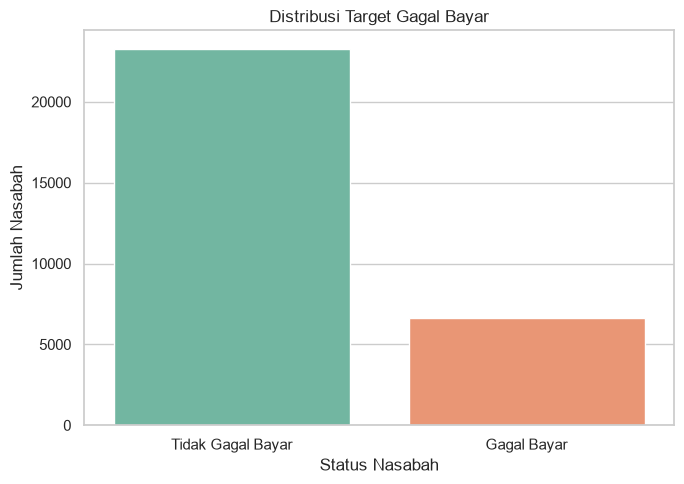

In [8]:
target_counts = df[TARGET].value_counts().sort_index()

target_labels = {
    0: "Tidak Gagal Bayar",
    1: "Gagal Bayar"
}

print("Distribusi target:")
display(
    target_counts.rename(index=target_labels)
    .to_frame("Jumlah Nasabah")
)

print("\nPersentase target:")
display(
    (df[TARGET].value_counts(normalize=True).sort_index() * 100)
    .rename(index=target_labels)
    .round(2)
    .to_frame("Persentase (%)")
)

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=TARGET,
    hue=TARGET,
    order=[0, 1],
    hue_order=[0, 1],
    palette="Set2",
    legend=False
)

plt.xticks([0, 1], ["Tidak Gagal Bayar", "Gagal Bayar"])
plt.title("Distribusi Target Gagal Bayar")
plt.xlabel("Status Nasabah")
plt.ylabel("Jumlah Nasabah")
plt.tight_layout()
plt.show()

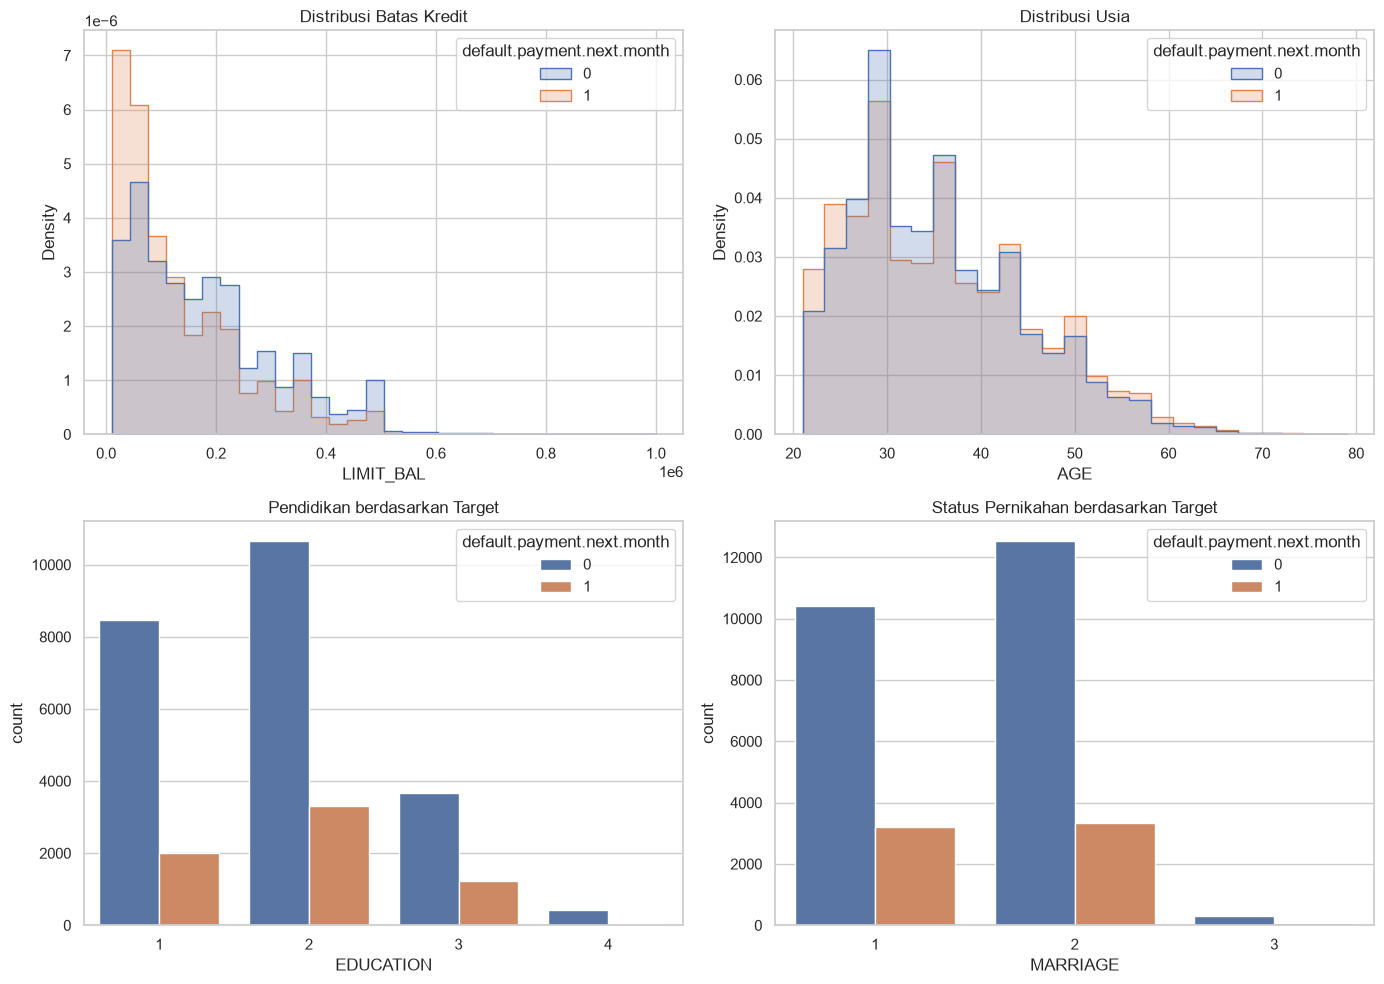

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(
    data=df, x="LIMIT_BAL", hue=TARGET,
    bins=30, element="step", stat="density",
    common_norm=False, ax=axes[0, 0]
)
axes[0, 0].set_title("Distribusi Batas Kredit")

sns.histplot(
    data=df, x="AGE", hue=TARGET,
    bins=25, element="step", stat="density",
    common_norm=False, ax=axes[0, 1]
)
axes[0, 1].set_title("Distribusi Usia")

sns.countplot(
    data=df, x="EDUCATION", hue=TARGET,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Pendidikan berdasarkan Target")

sns.countplot(
    data=df, x="MARRIAGE", hue=TARGET,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Status Pernikahan berdasarkan Target")

plt.tight_layout()
plt.show()

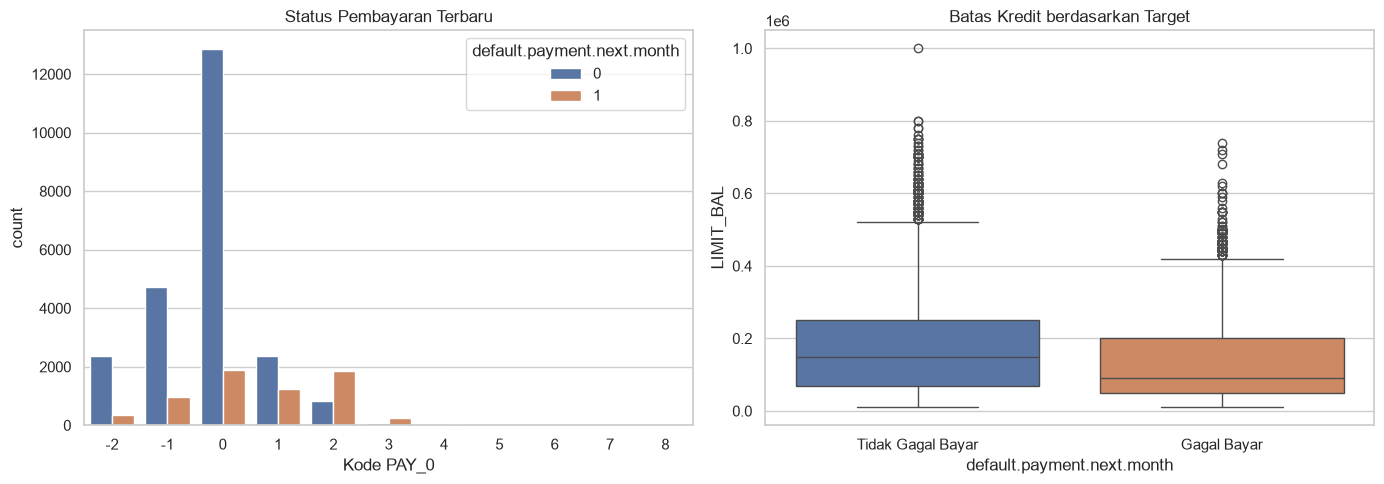

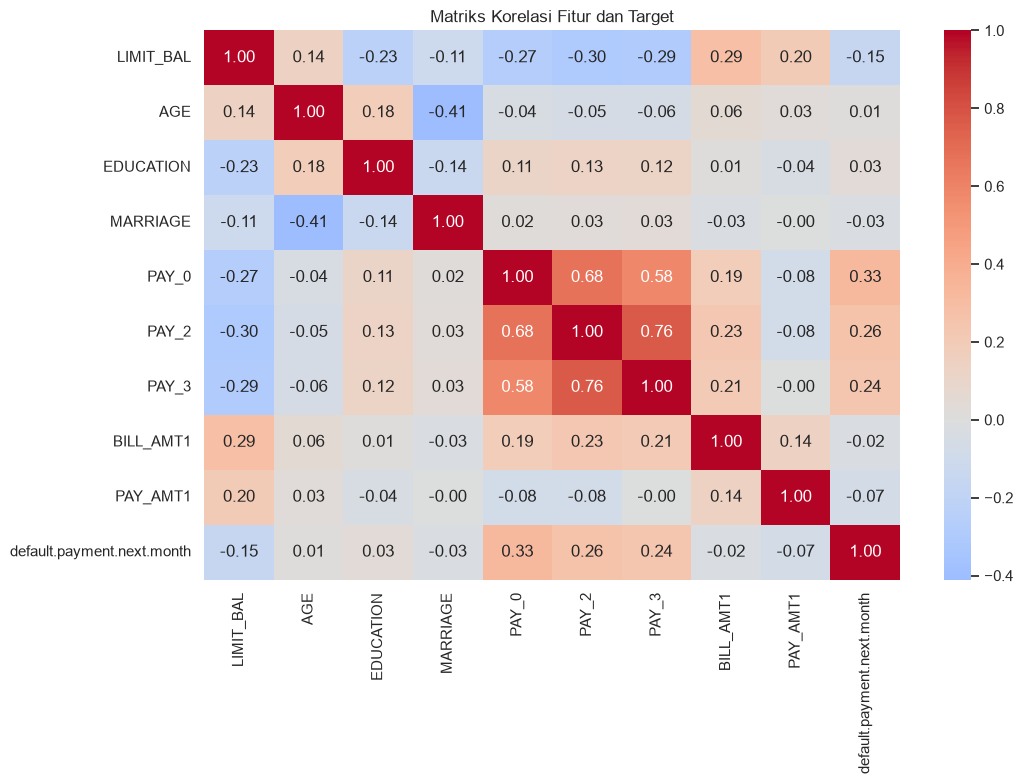

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df,
    x="PAY_0",
    hue=TARGET,
    ax=axes[0]
)
axes[0].set_title("Status Pembayaran Terbaru")
axes[0].set_xlabel("Kode PAY_0")

sns.boxplot(
    data=df,
    x=TARGET,
    y="LIMIT_BAL",
    hue=TARGET,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Batas Kredit berdasarkan Target")
axes[1].set_xticks([0, 1], ["Tidak Gagal Bayar", "Gagal Bayar"])

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Matriks Korelasi Fitur dan Target")
plt.tight_layout()
plt.show()

In [11]:
X = df[FEATURES].copy()
y = df[TARGET].copy()

CATEGORICAL_FEATURES = ["EDUCATION", "MARRIAGE"]

NUMERICAL_FEATURES = [
    col for col in FEATURES
    if col not in CATEGORICAL_FEATURES
]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nProporsi target training:")
display(y_train.value_counts(normalize=True).rename("Proporsi"))

print("\nProporsi target testing:")
display(y_test.value_counts(normalize=True).rename("Proporsi"))

Jumlah data training: 23884
Jumlah data testing: 5972

Proporsi target training:


default.payment.next.month
0   0.7786
1   0.2214
Name: Proporsi, dtype: float64


Proporsi target testing:


default.payment.next.month
0   0.7786
1   0.2214
Name: Proporsi, dtype: float64

Data dibagi 80% untuk training dan 20% untuk testing. stratify=y menjaga proporsi kelas relatif konsisten pada kedua bagian.

Cell 12 — Menyiapkan preprocessing dan dua model
Tipe: Code

Kita bandingkan dua model dengan fitur dan pembagian data yang sama:
1. Logistic Regression tanpa SMOTE.
2. Logistic Regression dengan SMOTENC.
SMOTENC dipilih karena data memiliki fitur numerik serta kategori pendidikan dan pernikahan. Berbeda dari SMOTE biasa, SMOTENC dirancang untuk menangani data campuran numerik-kategorikal.

In [12]:
def create_preprocessor():
    numeric_pipeline = SklearnPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = SklearnPipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        (
            "numeric",
            numeric_pipeline,
            NUMERICAL_FEATURES
        ),
        (
            "categorical",
            categorical_pipeline,
            CATEGORICAL_FEATURES
        )
    ])


# Model baseline tanpa SMOTE.
model_baseline = SklearnPipeline([
    ("preprocessor", create_preprocessor()),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    )
])

# SMOTENC mengenali EDUCATION dan MARRIAGE
# sebagai fitur kategorikal sebelum one-hot encoding.
categorical_indices = [
    FEATURES.index(col)
    for col in CATEGORICAL_FEATURES
]

model_smote = ImbPipeline([
    (
        "sampler",
        SMOTENC(
            categorical_features=categorical_indices,
            random_state=RANDOM_STATE
        )
    ),
    ("preprocessor", create_preprocessor()),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        )
    )
])

print("Pipeline baseline dan SMOTENC berhasil dibuat.")
print("Indeks fitur kategorikal:", categorical_indices)

Pipeline baseline dan SMOTENC berhasil dibuat.
Indeks fitur kategorikal: [2, 3]


In [13]:
print("Training Logistic Regression tanpa SMOTE...")

model_baseline.fit(X_train, y_train)

print("Training Logistic Regression dengan SMOTENC...")

model_smote.fit(X_train, y_train)

print("\nKedua model selesai dilatih.")

Training Logistic Regression tanpa SMOTE...
Training Logistic Regression dengan SMOTENC...

Kedua model selesai dilatih.


In [14]:
def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

    return results, y_pred, y_prob


baseline_results, baseline_pred, baseline_prob = evaluate_model(
    model_baseline,
    X_test,
    y_test,
    "Logistic Regression"
)

smote_results, smote_pred, smote_prob = evaluate_model(
    model_smote,
    X_test,
    y_test,
    "Logistic Regression + SMOTENC"
)

comparison = pd.DataFrame([
    baseline_results,
    smote_results
]).set_index("Model")

display(comparison.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8069,0.7007,0.2231,0.3385,0.7072
Logistic Regression + SMOTENC,0.6490,0.3427,0.6377,0.4458,0.6990


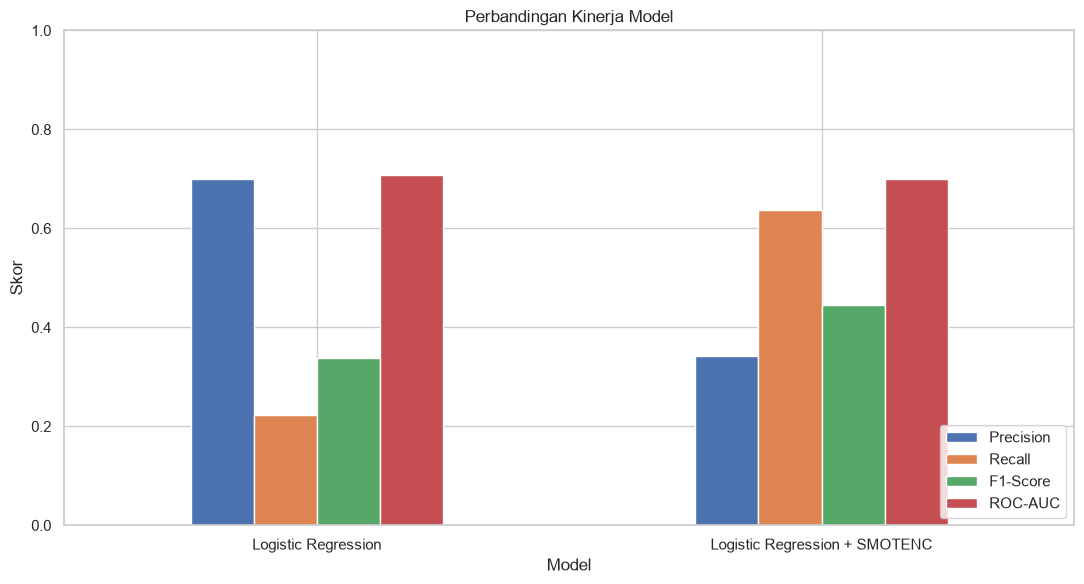

In [15]:
metrics_to_plot = [
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

comparison[metrics_to_plot].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Perbandingan Kinerja Model")
plt.ylabel("Skor")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Interpretasi metrik:
- Precision: proporsi prediksi gagal bayar yang benar-benar gagal bayar.
- Recall: proporsi nasabah yang benar-benar gagal bayar dan berhasil terdeteksi.
- F1-score: keseimbangan antara Precision dan Recall.
- ROC-AUC: kemampuan model membedakan kelas positif dan negatif pada berbagai threshold.
Akurasi tetap dicatat, tetapi tidak cukup dijadikan patokan utama jika jumlah nasabah gagal bayar jauh lebih sedikit daripada nasabah yang tidak gagal bayar.

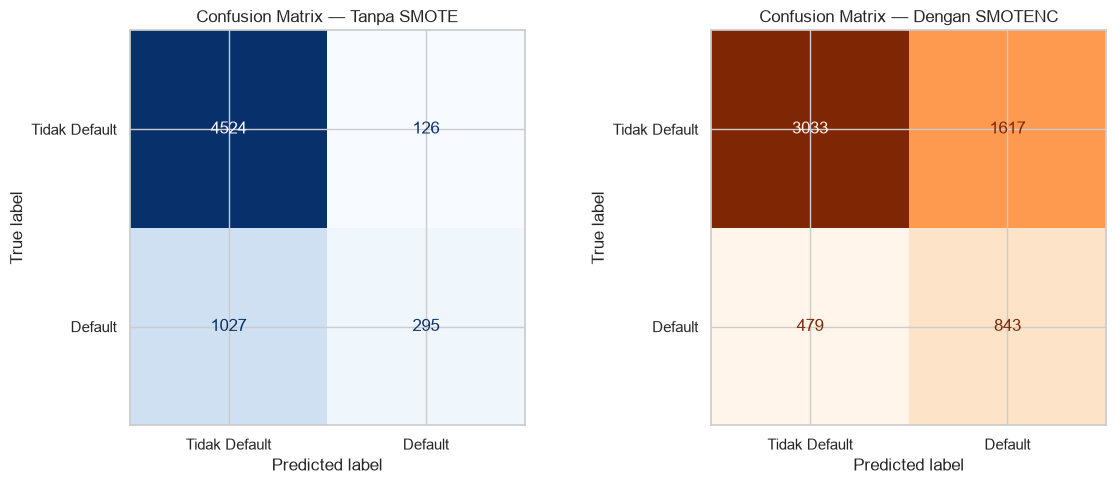

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_pred,
    labels=[0, 1],
    display_labels=["Tidak Default", "Default"],
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Confusion Matrix — Tanpa SMOTE")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    smote_pred,
    labels=[0, 1],
    display_labels=["Tidak Default", "Default"],
    cmap="Oranges",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Confusion Matrix — Dengan SMOTENC")

plt.tight_layout()
plt.show()

In [25]:
print("=== TANPA SMOTE ===")
print(confusion_matrix(y_test, baseline_pred))

print("\n=== DENGAN SMOTENC ===")
print(confusion_matrix(y_test, smote_pred))

=== TANPA SMOTE ===
[[4524  126]
 [1027  295]]

=== DENGAN SMOTENC ===
[[3033 1617]
 [ 479  843]]


In [17]:
print("Laporan klasifikasi — Tanpa SMOTE")
print(
    classification_report(
        y_test,
        baseline_pred,
        target_names=["Tidak Default", "Default"],
        zero_division=0
    )
)

print("Laporan klasifikasi — Dengan SMOTENC")
print(
    classification_report(
        y_test,
        smote_pred,
        target_names=["Tidak Default", "Default"],
        zero_division=0
    )
)

Laporan klasifikasi — Tanpa SMOTE
               precision    recall  f1-score   support

Tidak Default       0.81      0.97      0.89      4650
      Default       0.70      0.22      0.34      1322

     accuracy                           0.81      5972
    macro avg       0.76      0.60      0.61      5972
 weighted avg       0.79      0.81      0.77      5972

Laporan klasifikasi — Dengan SMOTENC
               precision    recall  f1-score   support

Tidak Default       0.86      0.65      0.74      4650
      Default       0.34      0.64      0.45      1322

     accuracy                           0.65      5972
    macro avg       0.60      0.64      0.59      5972
 weighted avg       0.75      0.65      0.68      5972



Kondisi	Arti bagi perusahaan
True Positive (TP)	| Nasabah berisiko berhasil terdeteksi
True Negative (TN)	| Nasabah tidak berisiko teridentifikasi dengan benar
False Positive (FP)	| Nasabah yang tidak gagal bayar salah ditandai berisiko
False Negative (FN)	| Nasabah yang gagal bayar justru diprediksi tidak berisiko

Dalam manajemen risiko, False Negative dapat menyebabkan kerugian kredit yang tidak terantisipasi. False Positive juga merugikan karena bisa memicu pemeriksaan tambahan atau penolakan kredit yang sebenarnya layak. Bobot kerugian keduanya harus dipertimbangkan dalam penentuan threshold operasional.

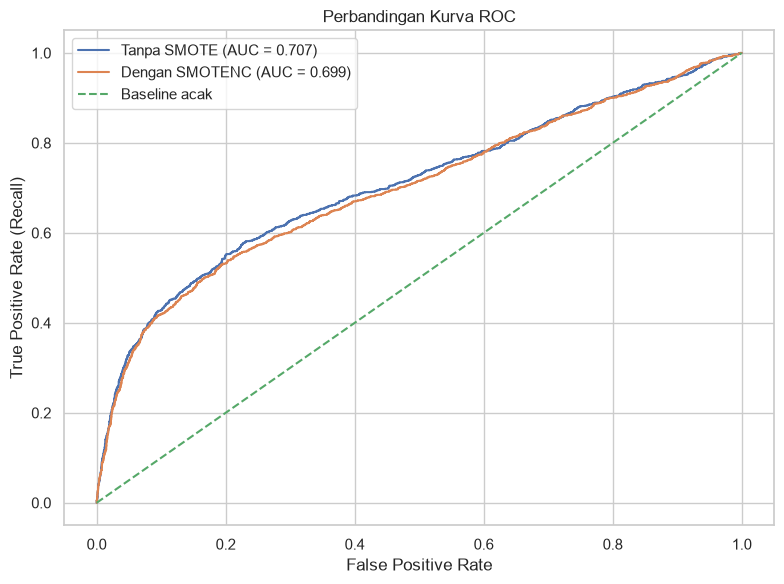

In [18]:
fpr_base, tpr_base, _ = roc_curve(y_test, baseline_prob)
fpr_smote, tpr_smote, _ = roc_curve(y_test, smote_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_base,
    tpr_base,
    label=f"Tanpa SMOTE (AUC = {baseline_results['ROC-AUC']:.3f})"
)

plt.plot(
    fpr_smote,
    tpr_smote,
    label=f"Dengan SMOTENC (AUC = {smote_results['ROC-AUC']:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Baseline acak")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Perbandingan Kurva ROC")
plt.legend()
plt.tight_layout()
plt.show()

Kurva ROC memperlihatkan pertukaran antara True Positive Rate dan False Positive Rate. AUC yang lebih tinggi menunjukkan kemampuan pemeringkatan kelas yang lebih baik, tetapi tidak otomatis berarti model memiliki threshold operasional terbaik.

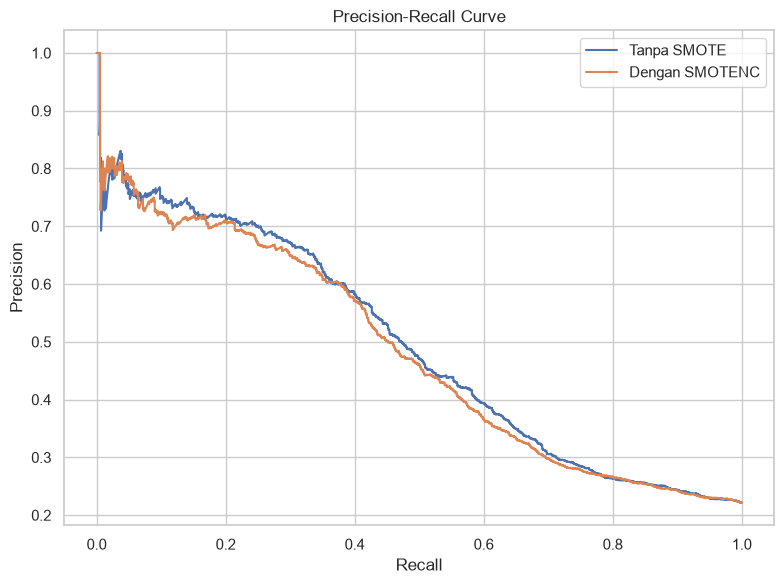

In [19]:
precision_base, recall_base, _ = precision_recall_curve(
    y_test, baseline_prob
)

precision_smote, recall_smote, _ = precision_recall_curve(
    y_test, smote_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_base,
    precision_base,
    label="Tanpa SMOTE"
)

plt.plot(
    recall_smote,
    precision_smote,
    label="Dengan SMOTENC"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()

Kurva ini membantu mengevaluasi model ketika perhatian utama adalah deteksi nasabah yang berpotensi gagal bayar. Recall yang lebih tinggi sering dicapai dengan menerima lebih banyak False Positive, sehingga Precision juga perlu diperiksa.

In [20]:
comparison_sorted = comparison.sort_values(
    by=["F1-Score", "Recall", "ROC-AUC"],
    ascending=False
)

best_name = comparison_sorted.index[0]

models = {
    "Logistic Regression": model_baseline,
    "Logistic Regression + SMOTENC": model_smote
}

predictions = {
    "Logistic Regression": baseline_pred,
    "Logistic Regression + SMOTENC": smote_pred
}

probabilities = {
    "Logistic Regression": baseline_prob,
    "Logistic Regression + SMOTENC": smote_prob
}

best_model = models[best_name]
best_pred = predictions[best_name]
best_prob = probabilities[best_name]

print("Peringkat model:")
display(comparison_sorted.round(4))

print("\nModel terpilih:", best_name)
print("F1-score:", round(f1_score(y_test, best_pred), 4))
print("Recall:", round(recall_score(y_test, best_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, best_prob), 4))

Peringkat model:


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression + SMOTENC,0.6490,0.3427,0.6377,0.4458,0.6990
Logistic Regression,0.8069,0.7007,0.2231,0.3385,0.7072



Model terpilih: Logistic Regression + SMOTENC
F1-score: 0.4458
Recall: 0.6377
ROC-AUC: 0.699


,Fitur,Koefisien,Odds Ratio
10,categorical__EDUCATION_4,-1.8826,0.1522
13,categorical__MARRIAGE_3,-1.0319,0.3563
2,numeric__PAY_0,0.6762,1.9665
8,categorical__EDUCATION_2,0.6227,1.8639
7,categorical__EDUCATION_1,0.5381,1.7128
11,categorical__MARRIAGE_1,0.2689,1.3085
6,numeric__PAY_AMT1,-0.2642,0.7678
0,numeric__LIMIT_BAL,-0.1632,0.8494
5,numeric__BILL_AMT1,-0.1453,0.8647
4,numeric__PAY_3,0.1447,1.1556


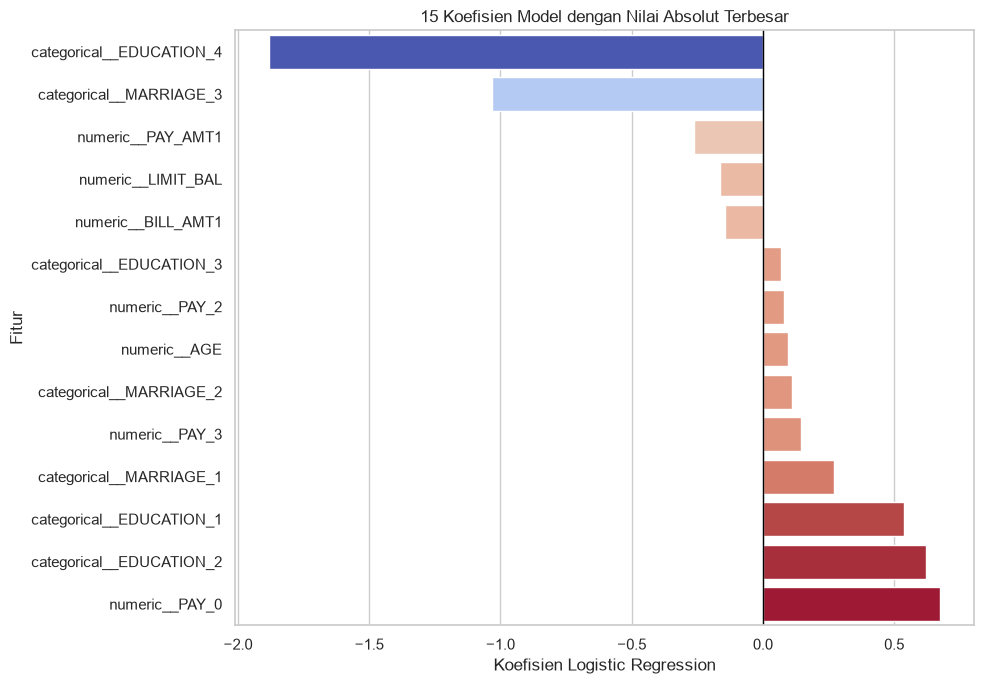

In [21]:
preprocessor = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Fitur": feature_names,
    "Koefisien": classifier.coef_[0]
})

coefficients["Odds Ratio"] = np.exp(
    np.clip(coefficients["Koefisien"], -500, 500)
)

coefficients["Absolut Koefisien"] = (
    coefficients["Koefisien"].abs()
)

coefficients = coefficients.sort_values(
    "Absolut Koefisien",
    ascending=False
)

display(coefficients.drop(columns="Absolut Koefisien").round(4))

plt.figure(figsize=(10, 7))

plot_data = coefficients.head(15).sort_values("Koefisien")

sns.barplot(
    data=plot_data,
    x="Koefisien",
    y="Fitur",
    hue="Koefisien",
    palette="coolwarm",
    legend=False
)

plt.axvline(0, color="black", linewidth=1)
plt.title("15 Koefisien Model dengan Nilai Absolut Terbesar")
plt.xlabel("Koefisien Logistic Regression")
plt.ylabel("Fitur")
plt.tight_layout()
plt.show()

Interpretasi:
- Koefisien positif menunjukkan kenaikan nilai fitur berkaitan dengan kenaikan log-odds gagal bayar, dengan fitur lain dianggap tetap.
- Koefisien negatif menunjukkan hubungan sebaliknya.
- Untuk fitur numerik yang distandardisasi, interpretasi koefisien mengacu pada perubahan satu standar deviasi.
- Koefisien fitur one-hot membandingkan kategori dengan kategori referensi yang digunakan encoder.
Koefisien bukan bukti bahwa suatu fitur menyebabkan gagal bayar. Model ini mengidentifikasi hubungan statistik berdasarkan data historis.

In [22]:
best_metrics = comparison.loc[best_name]

print("=" * 55)
print("RINGKASAN HASIL TA-03")
print("=" * 55)

print("Dataset                  :", DATA_PATH.name)
print("Jumlah data              :", len(df))
print("Jumlah fitur             :", len(FEATURES))
print("Model terpilih           :", best_name)
print("Accuracy                 :", round(best_metrics["Accuracy"], 4))
print("Precision                :", round(best_metrics["Precision"], 4))
print("Recall                   :", round(best_metrics["Recall"], 4))
print("F1-Score                 :", round(best_metrics["F1-Score"], 4))
print("ROC-AUC                  :", round(best_metrics["ROC-AUC"], 4))

cm = confusion_matrix(y_test, best_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("\nTrue Negative (TN)       :", tn)
print("False Positive (FP)      :", fp)
print("False Negative (FN)      :", fn)
print("True Positive (TP)       :", tp)

print("\nJumlah nasabah gagal bayar yang terdeteksi:", tp)
print("Jumlah nasabah gagal bayar yang terlewat  :", fn)

RINGKASAN HASIL TA-03
Dataset                  : UCI_Credit_Card.csv
Jumlah data              : 29856
Jumlah fitur             : 9
Model terpilih           : Logistic Regression + SMOTENC
Accuracy                 : 0.649
Precision                : 0.3427
Recall                   : 0.6377
F1-Score                 : 0.4458
ROC-AUC                  : 0.699

True Negative (TN)       : 3033
False Positive (FP)      : 1617
False Negative (FN)      : 479
True Positive (TP)       : 843

Jumlah nasabah gagal bayar yang terdeteksi: 843
Jumlah nasabah gagal bayar yang terlewat  : 479


In [23]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "credit_risk_model.joblib"
METADATA_PATH = MODEL_DIR / "model_metadata.json"
METRICS_PATH = MODEL_DIR / "model_comparison.csv"
COEFFICIENTS_PATH = MODEL_DIR / "model_coefficients.csv"

# Simpan seluruh pipeline terpilih, bukan hanya classifier.
joblib.dump(best_model, MODEL_PATH)

# Simpan hasil evaluasi kedua model.
comparison.to_csv(METRICS_PATH)

# Simpan koefisien model.
coefficients.to_csv(COEFFICIENTS_PATH, index=False)

metadata = {
    "project": "TA-03 Credit Risk Prediction",
    "algorithm": "Logistic Regression",
    "selected_model": best_name,
    "target": TARGET,
    "positive_class": 1,
    "negative_class": 0,
    "default_threshold": 0.5,
    "features": FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "numerical_features": NUMERICAL_FEATURES,
    "education_options": {
        "1": "Graduate School",
        "2": "University",
        "3": "High School",
        "4": "Others"
    },
    "marriage_options": {
        "1": "Married",
        "2": "Single",
        "3": "Others"
    },
    "metrics": {
        metric: float(best_metrics[metric])
        for metric in [
            "Accuracy",
            "Precision",
            "Recall",
            "F1-Score",
            "ROC-AUC"
        ]
    },
    "random_state": RANDOM_STATE
}

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print("Artefak berhasil disimpan:")
print("Model      :", MODEL_PATH)
print("Metadata   :", METADATA_PATH)
print("Evaluasi   :", METRICS_PATH)
print("Koefisien  :", COEFFICIENTS_PATH)

Artefak berhasil disimpan:
Model      : d:\Semester5 ML\TA3_301240032\models\credit_risk_model.joblib
Metadata   : d:\Semester5 ML\TA3_301240032\models\model_metadata.json
Evaluasi   : d:\Semester5 ML\TA3_301240032\models\model_comparison.csv
Koefisien  : d:\Semester5 ML\TA3_301240032\models\model_coefficients.csv


In [24]:
loaded_model = joblib.load(MODEL_PATH)

# Ambil satu baris dari data uji sebagai contoh input.
sample = X_test.iloc[[0]].copy()

prediction = int(loaded_model.predict(sample)[0])
probability = float(loaded_model.predict_proba(sample)[0, 1])

print("Contoh data nasabah:")
display(sample)

print("\nHasil aktual:", int(y_test.iloc[0]))
print("Hasil prediksi:", prediction)
print("Probabilitas gagal bayar:", f"{probability:.2%}")

if prediction == 1:
    print("Status: Berisiko Gagal Bayar")
else:
    print("Status: Tidak Berisiko")

print("\nModel tersimpan berhasil dimuat dan digunakan.")

Contoh data nasabah:


,LIMIT_BAL,AGE,EDUCATION,MARRIAGE,PAY_0,PAY_2,PAY_3,BILL_AMT1,PAY_AMT1
29593,"230,000.0000",39,3,1,-1,-1,0,"2,606.0000","2,990.0000"



Hasil aktual: 0
Hasil prediksi: 0
Probabilitas gagal bayar: 26.21%
Status: Tidak Berisiko

Model tersimpan berhasil dimuat dan digunakan.
